# 07 — Final detector calibration

## Objective

This notebook turns the robust model selected in notebook **06B** into the final frozen detector.

The key design rule is:

> **The same frozen GMMs used to compute calibration scores are the models saved for later inference.**

That prevents the score-distribution shift seen in the earlier m-FCC calibration experiment, where
thresholds were calibrated on one set of models and then applied to retrained models.

## Inputs

- `data/processed/calls.csv`
- `data/processed/feature_comparison/call_feature_sets.joblib`
- `data/processed/robust_model_selection/selected_robust_configuration.json`

## Expected robust configuration

Notebook 06B currently recommends approximately:

- feature representation: **20 PLP-RASTA**
- GMM order: **M = 4**
- validation unit: **source WAV**

The notebook reads the JSON rather than trusting those values by memory.

## Calibration protocol

`[ROBUSTNESS DECISION]`

1. Build one fixed, deterministic **recording-level TRAIN/CALIBRATION split**.
2. A source WAV belongs only to TRAIN or CALIBRATION.
3. Fit one diagonal GMM per species using **all labelled calls from TRAIN WAVs**.
4. Freeze the fitted GMMs.
5. Score only CALIBRATION calls.
6. For each species `k`, calculate

\[
LLR_k(X)
=
s_k(X)
-
{\rm median}_{j\neq k}\,s_j(X),
\]

where `s_k(X)` is the mean frame log-likelihood of the complete call under GMM `k`.
7. Build one-vs-all ROC curves.
8. Choose one threshold per species under an `FPR <= 5%` constraint.
9. Save the frozen GMMs and thresholds together.

## Paper versus our model

`[PAPER]`

The article used m-FCC, high-order GMMs, likelihood-ratio verification and species-specific thresholds.
Its final published threshold vector is retained only as a reference.

`[OUR FINAL MODEL]`

The robust selection uses the feature representation and model order supported by our recovered corpus.
Therefore **old m-FCC thresholds are not transferable and are not reused**.

## Important evaluation limitation

Thresholds are selected on the CALIBRATION set and calibration metrics are reported on that same set.
They are useful for understanding the operating point, but they are **not an independent test-set
performance estimate**.

In [1]:
from pathlib import Path
import json
import math
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import kmeans_plusplus
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    auc,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_curve,
)
from sklearn.mixture import GaussianMixture

pd.set_option("display.width", 190)
pd.set_option("display.max_rows", 180)
pd.set_option("display.max_columns", 100)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"

CALLS_PATH = (
    PROCESSED_DIR / "calls.csv"
)

FEATURE_CACHE_PATH = (
    PROCESSED_DIR
    / "feature_comparison"
    / "call_feature_sets.joblib"
)

ROBUST_SELECTION_PATH = (
    PROCESSED_DIR
    / "robust_model_selection"
    / "selected_robust_configuration.json"
)

RESULTS_DIR = (
    PROCESSED_DIR
    / "final_detector_calibration"
)

MODEL_DIR = (
    REPO_ROOT
    / "models"
    / "gmm_robust_final"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for path in (
    CALLS_PATH,
    FEATURE_CACHE_PATH,
    ROBUST_SELECTION_PATH,
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required input: {path}"
        )

print("Repository root :", REPO_ROOT)
print("Robust selection:", ROBUST_SELECTION_PATH)
print("Feature cache   :", FEATURE_CACHE_PATH)
print("Results         :", RESULTS_DIR)
print("Models          :", MODEL_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Robust selection: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\robust_model_selection\selected_robust_configuration.json
Feature cache   : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\feature_comparison\call_feature_sets.joblib
Results         : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_detector_calibration
Models          : C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_robust_final


## 2. Load the robust model selection

The detector configuration comes from notebook 06B's exported JSON.

The experimental `training_seconds_target` is retained as provenance, but the final detector does not
throw away labelled TRAIN data just to force exactly 18 seconds. Once the model order has been selected,
the GMMs are fit using all calls available in the TRAIN recordings.

In [2]:
with open(
    ROBUST_SELECTION_PATH,
    "r",
    encoding="utf-8",
) as f:
    ROBUST_SELECTION = json.load(f)

FEATURE_NAME = str(
    ROBUST_SELECTION[
        "feature"
    ]
)

FEATURE_DIM = int(
    ROBUST_SELECTION[
        "feature_dimensions"
    ]
)

USABLE_CODES = tuple(
    ROBUST_SELECTION[
        "classes"
    ]
)

EXCLUDED_CLASS = str(
    ROBUST_SELECTION.get(
        "excluded_class",
        "f09",
    )
)

RECOMMENDED = (
    ROBUST_SELECTION[
        "recommended_parsimonious"
    ]
)

N_COMPONENTS = int(
    RECOMMENDED[
        "n_components"
    ]
)

EXPERIMENTAL_TRAINING_TARGET_SECONDS = int(
    RECOMMENDED[
        "training_seconds_target"
    ]
)

VALIDATION_UNIT = str(
    ROBUST_SELECTION[
        "validation_unit"
    ]
)

print("Feature                       :", FEATURE_NAME)
print("Feature dimensions            :", FEATURE_DIM)
print("GMM components                :", N_COMPONENTS)
print(
    "Experimental training target  :",
    EXPERIMENTAL_TRAINING_TARGET_SECONDS,
    "s",
)
print("Validation unit               :", VALIDATION_UNIT)
print("Classes                       :", USABLE_CODES)
print("Excluded class                :", EXCLUDED_CLASS)

if VALIDATION_UNIT != "source_wav":
    warnings.warn(
        f"Notebook 06B reports validation_unit={VALIDATION_UNIT!r}; "
        "this detector still enforces source-WAV separation."
    )

Feature                       : 20_PLP_RASTA
Feature dimensions            : 20
GMM components                : 4
Experimental training target  : 18 s
Validation unit               : source_wav
Classes                       : ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')
Excluded class                : f09


## 3. Load calls and cached features

In [3]:
calls = (
    pd.read_csv(
        CALLS_PATH
    )
    .copy()
    .reset_index(drop=True)
)

required_columns = {
    "code",
    "species",
    "wav",
    "seconds",
}

missing_columns = (
    required_columns
    - set(calls.columns)
)

if missing_columns:
    raise ValueError(
        f"calls.csv is missing: {sorted(missing_columns)}"
    )

calls["call_id"] = [
    f"call_{i:04d}"
    for i in range(
        len(calls)
    )
]

calls["recording_group"] = (
    calls["wav"]
    .astype(str)
    .str.strip()
    .str.lower()
)

CALLS_BY_ID = (
    calls.set_index(
        "call_id",
        drop=False,
    )
)

CALL_FEATURES = joblib.load(
    FEATURE_CACHE_PATH
)

expected_ids = set(
    calls["call_id"]
)

cached_ids = set(
    CALL_FEATURES
)

if expected_ids != cached_ids:
    raise RuntimeError(
        "Feature cache and calls.csv do not contain the same call IDs."
    )

bad_features = []

for call_id in calls["call_id"]:

    feature_sets = (
        CALL_FEATURES[
            call_id
        ]
    )

    if FEATURE_NAME not in feature_sets:
        bad_features.append(
            (
                call_id,
                "missing",
            )
        )
        continue

    X = np.asarray(
        feature_sets[
            FEATURE_NAME
        ]
    )

    if (
        X.ndim != 2
        or X.shape[1] != FEATURE_DIM
        or len(X) == 0
        or not np.isfinite(X).all()
    ):
        bad_features.append(
            (
                call_id,
                X.shape,
            )
        )

if bad_features:
    raise RuntimeError(
        f"Invalid selected-feature matrices: {bad_features[:10]}"
    )

usable_calls = (
    calls[
        calls["code"].isin(
            USABLE_CODES
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("All calls             :", len(calls))
print("Usable calls          :", len(usable_calls))
print(
    "Independent recordings:",
    usable_calls[
        "recording_group"
    ].nunique(),
)
print("Feature validation    : OK")

All calls             : 1461
Usable calls          : 1459
Independent recordings: 66
Feature validation    : OK


## 4. Species/recording inventory

This matters especially because some species are represented by only a few independent WAVs.
The split below therefore searches many deterministic candidate assignments instead of blindly applying
a generic 80/20 random split.

In [4]:
inventory = (
    usable_calls
    .groupby(
        [
            "code",
            "species",
        ],
        as_index=False,
    )
    .agg(
        n_calls=(
            "call_id",
            "size",
        ),
        total_seconds=(
            "seconds",
            "sum",
        ),
        n_recordings=(
            "recording_group",
            "nunique",
        ),
    )
    .sort_values(
        "code"
    )
)

display(
    inventory.round(3)
)

if (
    inventory[
        "n_recordings"
    ] < 2
).any():
    raise RuntimeError(
        "Every detector class needs at least two independent source WAVs "
        "to create a leakage-free TRAIN/CALIBRATION split."
    )

,code,species,n_calls,total_seconds,n_recordings
0,f01,Boana alfaroi,98,44.72,5
1,f02,Dendropsophus bifurcus,99,41.72,10
2,f03,Boana cinerascens,169,102.58,8
3,f04,Pristimantis conspicillatus,186,77.94,9
4,f05,Leptodactylus discodactylus,340,114.36,3
5,f06,Osteocephalus fuscifacies,54,24.94,5
6,f07,Boana lanciformis,101,57.84,7
7,f08,Rhinella margaritifera,96,102.66,7
8,f10,Engystomops petersi,316,134.00,12


## 5. Fixed global recording-level TRAIN/CALIBRATION split

The split is built globally because one physical WAV may contain annotations associated with more than
one species.

### Target

We aim for roughly **25% of each species' labelled duration in CALIBRATION**, while requiring:

- each class appears in TRAIN;
- each class appears in CALIBRATION;
- TRAIN and CALIBRATION contain disjoint WAV sets;
- every TRAIN class has enough feature frames to fit `M` Gaussian components.

Because WAVs are indivisible groups, exact 75/25 balancing is generally impossible. We evaluate many
reproducible candidate calibration-WAV sets and choose the valid split with the lowest imbalance score.

In [5]:
CALIBRATION_FRACTION_TARGET = 0.25

SPLIT_SEED = 20260821
SPLIT_SEARCH_ATTEMPTS = 10000

ALL_RECORDINGS = np.array(
    sorted(
        usable_calls[
            "recording_group"
        ].unique()
    ),
    dtype=object,
)

TOTAL_SECONDS_BY_CODE = (
    usable_calls
    .groupby(
        "code"
    )["seconds"]
    .sum()
    .reindex(
        USABLE_CODES
    )
)

TOTAL_CALLS_BY_CODE = (
    usable_calls
    .groupby(
        "code"
    )["call_id"]
    .size()
    .reindex(
        USABLE_CODES
    )
)


def evaluate_calibration_recordings(
    calibration_recordings,
):
    calibration_recordings = set(
        calibration_recordings
    )

    train_recordings = (
        set(ALL_RECORDINGS)
        - calibration_recordings
    )

    if not calibration_recordings:
        return None

    if not train_recordings:
        return None

    if not train_recordings.isdisjoint(
        calibration_recordings
    ):
        raise AssertionError(
            "Recording leakage detected."
        )

    rows = []
    imbalance = 0.0

    for code in USABLE_CODES:

        species_calls = (
            usable_calls[
                usable_calls[
                    "code"
                ] == code
            ]
        )

        train_rows = (
            species_calls[
                species_calls[
                    "recording_group"
                ].isin(
                    train_recordings
                )
            ]
        )

        calibration_rows = (
            species_calls[
                species_calls[
                    "recording_group"
                ].isin(
                    calibration_recordings
                )
            ]
        )

        if train_rows.empty or calibration_rows.empty:
            return None

        train_groups = set(
            train_rows[
                "recording_group"
            ]
        )

        calibration_groups = set(
            calibration_rows[
                "recording_group"
            ]
        )

        if not train_groups.isdisjoint(
            calibration_groups
        ):
            raise AssertionError(
                f"Recording leakage for {code}."
            )

        calibration_seconds = float(
            calibration_rows[
                "seconds"
            ].sum()
        )

        total_seconds = float(
            species_calls[
                "seconds"
            ].sum()
        )

        calibration_fraction = (
            calibration_seconds
            / total_seconds
        )

        calibration_call_fraction = (
            len(calibration_rows)
            / len(species_calls)
        )

        # Balance both labelled duration and number of calls.
        imbalance += (
            calibration_fraction
            - CALIBRATION_FRACTION_TARGET
        ) ** 2

        imbalance += 0.25 * (
            calibration_call_fraction
            - CALIBRATION_FRACTION_TARGET
        ) ** 2

        rows.append({
            "code":
                code,
            "n_train_calls":
                len(train_rows),
            "n_calibration_calls":
                len(calibration_rows),
            "train_seconds":
                float(
                    train_rows[
                        "seconds"
                    ].sum()
                ),
            "calibration_seconds":
                calibration_seconds,
            "calibration_fraction_seconds":
                calibration_fraction,
            "calibration_fraction_calls":
                calibration_call_fraction,
            "n_train_recordings":
                len(
                    train_groups
                ),
            "n_calibration_recordings":
                len(
                    calibration_groups
                ),
        })

    # Mild penalty for global fraction mismatch.
    global_calibration_fraction = (
        len(calibration_recordings)
        / len(ALL_RECORDINGS)
    )

    imbalance += 0.1 * (
        global_calibration_fraction
        - CALIBRATION_FRACTION_TARGET
    ) ** 2

    return {
        "score":
            imbalance,
        "train_recordings":
            train_recordings,
        "calibration_recordings":
            calibration_recordings,
        "audit":
            pd.DataFrame(
                rows
            ),
    }


best_split = None

rng = np.random.default_rng(
    SPLIT_SEED
)

n_recordings = len(
    ALL_RECORDINGS
)

target_n_calibration = max(
    1,
    int(
        round(
            CALIBRATION_FRACTION_TARGET
            * n_recordings
        )
    ),
)

candidate_sizes = sorted(
    set(
        size
        for size in (
            target_n_calibration - 2,
            target_n_calibration - 1,
            target_n_calibration,
            target_n_calibration + 1,
            target_n_calibration + 2,
        )
        if 1 <= size < n_recordings
    )
)

for attempt in range(
    SPLIT_SEARCH_ATTEMPTS
):
    size = candidate_sizes[
        attempt
        % len(candidate_sizes)
    ]

    calibration_recordings = set(
        rng.choice(
            ALL_RECORDINGS,
            size=size,
            replace=False,
        )
    )

    candidate = (
        evaluate_calibration_recordings(
            calibration_recordings
        )
    )

    if candidate is None:
        continue

    candidate[
        "attempt"
    ] = attempt

    if (
        best_split is None
        or candidate[
            "score"
        ] < best_split[
            "score"
        ]
    ):
        best_split = candidate


if best_split is None:
    raise RuntimeError(
        "Could not create a valid recording-level TRAIN/CALIBRATION split."
    )

TRAIN_RECORDINGS = set(
    best_split[
        "train_recordings"
    ]
)

CALIBRATION_RECORDINGS = set(
    best_split[
        "calibration_recordings"
    ]
)

assert TRAIN_RECORDINGS.isdisjoint(
    CALIBRATION_RECORDINGS
)

split_audit = (
    best_split[
        "audit"
    ]
    .copy()
)

print(
    "Selected split attempt:",
    best_split[
        "attempt"
    ],
)

print(
    "Global TRAIN recordings      :",
    len(
        TRAIN_RECORDINGS
    ),
)

print(
    "Global CALIBRATION recordings:",
    len(
        CALIBRATION_RECORDINGS
    ),
)

print(
    "Global calibration fraction  :",
    round(
        len(
            CALIBRATION_RECORDINGS
        )
        / len(
            ALL_RECORDINGS
        ),
        4,
    ),
)

display(
    split_audit.round(4)
)

Selected split attempt: 1659
Global TRAIN recordings      : 48
Global CALIBRATION recordings: 18
Global calibration fraction  : 0.2727


,code,n_train_calls,n_calibration_calls,train_seconds,calibration_seconds,calibration_fraction_seconds,calibration_fraction_calls,n_train_recordings,n_calibration_recordings
0,f01,79,19,36.08,8.64,0.1932,0.1939,4,1
1,f02,75,24,32.88,8.84,0.2119,0.2424,8,2
2,f03,143,26,87.08,15.50,0.1511,0.1538,7,1
3,f04,139,47,58.14,19.80,0.2540,0.2527,6,3
4,f05,205,135,66.80,47.56,0.4159,0.3971,2,1
5,f06,41,13,18.94,6.00,0.2406,0.2407,3,2
6,f07,84,17,48.50,9.34,0.1615,0.1683,6,1
7,f08,71,25,71.72,30.94,0.3014,0.2604,5,2
8,f10,240,76,101.82,32.18,0.2401,0.2405,7,5


## 6. Materialize the fixed split and prove there is no leakage

In [6]:
train_calls = (
    usable_calls[
        usable_calls[
            "recording_group"
        ].isin(
            TRAIN_RECORDINGS
        )
    ]
    .copy()
    .reset_index(drop=True)
)

calibration_calls = (
    usable_calls[
        usable_calls[
            "recording_group"
        ].isin(
            CALIBRATION_RECORDINGS
        )
    ]
    .copy()
    .reset_index(drop=True)
)

assert set(
    train_calls[
        "recording_group"
    ]
).isdisjoint(
    set(
        calibration_calls[
            "recording_group"
        ]
    )
)

assert set(
    train_calls[
        "call_id"
    ]
).isdisjoint(
    set(
        calibration_calls[
            "call_id"
        ]
    )
)

if (
    set(
        train_calls[
            "call_id"
        ]
    )
    | set(
        calibration_calls[
            "call_id"
        ]
    )
) != set(
    usable_calls[
        "call_id"
    ]
):
    raise AssertionError(
        "TRAIN/CALIBRATION partition is incomplete."
    )

print("TRAIN calls      :", len(train_calls))
print("CALIBRATION calls:", len(calibration_calls))
print("Recording leakage: NONE")
print("Call leakage     : NONE")
print("Partition        : COMPLETE")

TRAIN calls      : 1077
CALIBRATION calls: 382
Recording leakage: NONE
Call leakage     : NONE
Partition        : COMPLETE


## 7. Final GMM implementation

These are the actual models that will be saved.

Unlike the earlier parameter-search experiments, the final GMMs are trained using **all available
labelled calls from TRAIN recordings**. The selected model order `M` is the hyperparameter carried
forward from notebook 06B.

In [7]:
MODEL_SEED_BASE = 20260822


def species_number(
    code,
):
    digits = "".join(
        ch
        for ch in str(code)
        if ch.isdigit()
    )

    return int(
        digits
    ) if digits else 0


def stack_features(
    call_ids,
):
    return np.vstack([
        np.asarray(
            CALL_FEATURES[
                call_id
            ][
                FEATURE_NAME
            ]
        )
        for call_id in call_ids
    ])


def make_initial_parameters(
    X,
    n_components,
    seed,
):
    if len(X) < n_components:
        raise ValueError(
            f"Only {len(X)} frames available for M={n_components}."
        )

    means_init, _ = (
        kmeans_plusplus(
            X,
            n_clusters=n_components,
            random_state=seed,
        )
    )

    variance = np.maximum(
        np.var(
            X,
            axis=0,
            ddof=0,
        ),
        1e-12,
    )

    weights_init = np.full(
        n_components,
        1.0 / n_components,
    )

    precisions_init = np.tile(
        1.0 / variance,
        (
            n_components,
            1,
        ),
    )

    return (
        weights_init,
        means_init,
        precisions_init,
    )


def fit_final_gmm(
    X,
    code,
):
    seed = (
        MODEL_SEED_BASE
        + species_number(
            code
        )
    )

    (
        weights_init,
        means_init,
        precisions_init,
    ) = make_initial_parameters(
        X=X,
        n_components=N_COMPONENTS,
        seed=seed,
    )

    model = GaussianMixture(
        n_components=N_COMPONENTS,
        covariance_type="diag",
        weights_init=weights_init,
        means_init=means_init,
        precisions_init=precisions_init,
        n_init=1,
        random_state=seed,
        reg_covar=1e-6,
        max_iter=200,
        tol=1e-3,
        init_params="random",
    )

    with warnings.catch_warnings():
        warnings.simplefilter(
            "always",
            ConvergenceWarning,
        )

        model.fit(
            X
        )

    return model

## 8. Fit and freeze one final GMM per species

In [8]:
FINAL_MODELS = {}
model_audit_rows = []

for code in USABLE_CODES:

    code_train_calls = (
        train_calls[
            train_calls[
                "code"
            ] == code
        ]
    )

    train_ids = tuple(
        code_train_calls[
            "call_id"
        ]
    )

    X_train = stack_features(
        train_ids
    )

    model = fit_final_gmm(
        X=X_train,
        code=code,
    )

    FINAL_MODELS[
        code
    ] = model

    model_audit_rows.append({
        "code":
            code,
        "species":
            code_train_calls[
                "species"
            ].iloc[0],
        "n_components":
            model.n_components,
        "n_train_calls":
            len(
                code_train_calls
            ),
        "n_train_recordings":
            code_train_calls[
                "recording_group"
            ].nunique(),
        "train_seconds":
            float(
                code_train_calls[
                    "seconds"
                ].sum()
            ),
        "n_feature_frames":
            len(
                X_train
            ),
        "converged":
            bool(
                model.converged_
            ),
        "n_iter":
            int(
                model.n_iter_
            ),
    })

model_audit = pd.DataFrame(
    model_audit_rows
)

display(
    model_audit.round(3)
)

if not model_audit[
    "converged"
].all():
    warnings.warn(
        "At least one final GMM did not report convergence."
    )

,code,species,n_components,n_train_calls,n_train_recordings,train_seconds,n_feature_frames,converged,n_iter
0,f01,Boana alfaroi,4,79,4,36.08,6979,True,31
1,f02,Dendropsophus bifurcus,4,75,8,32.88,6351,True,17
2,f03,Boana cinerascens,4,143,7,87.08,16987,True,16
3,f04,Pristimantis conspicillatus,4,139,6,58.14,11211,True,13
4,f05,Leptodactylus discodactylus,4,205,2,66.80,12745,True,29
5,f06,Osteocephalus fuscifacies,4,41,3,18.94,3665,True,18
6,f07,Boana lanciformis,4,84,6,48.50,9448,True,16
7,f08,Rhinella margaritifera,4,71,5,71.72,14131,True,14
8,f10,Engystomops petersi,4,240,7,101.82,19644,True,27


## 9. Score every CALIBRATION call under every frozen GMM

For a complete call `X`, the species score is the mean frame log-likelihood:

\[
s_k(X)
=

rac{1}{T}
\sum_t
\log p(x_t \mid \lambda_k).
\]

The identification hypothesis is the model with the largest score.

In [9]:
score_rows = []

for row in calibration_calls.itertuples(
    index=False
):
    call_id = row.call_id

    X_call = np.asarray(
        CALL_FEATURES[
            call_id
        ][
            FEATURE_NAME
        ]
    )

    scores = {
        code: float(
            model.score_samples(
                X_call
            ).mean()
        )
        for code, model
        in FINAL_MODELS.items()
    }

    hypothesis = max(
        scores,
        key=scores.get,
    )

    score_row = {
        "call_id":
            call_id,
        "true_code":
            row.code,
        "species":
            row.species,
        "wav":
            row.wav,
        "recording_group":
            row.recording_group,
        "hypothesis":
            hypothesis,
        "identification_correct":
            hypothesis
            == row.code,
    }

    for code in USABLE_CODES:
        score_row[
            f"score_{code}"
        ] = scores[
            code
        ]

    score_rows.append(
        score_row
    )

calibration_scores = pd.DataFrame(
    score_rows
)

print(
    "Calibration calls scored:",
    len(
        calibration_scores
    ),
)

print(
    "Raw identification accuracy:",
    round(
        calibration_scores[
            "identification_correct"
        ].mean()
        * 100,
        3,
    ),
    "%",
)

Calibration calls scored: 382
Raw identification accuracy: 97.644 %


## 10. Compute one-vs-all LLR values

For every call and every class:

\[
LLR_k(X)
=
s_k(X)
-
{
m median}_{j
eq k}
s_j(X).
\]

This produces a verification score for each class, not merely for the winning hypothesis.

In [10]:
for code in USABLE_CODES:

    alternative_codes = [
        other
        for other in USABLE_CODES
        if other != code
    ]

    alternative_columns = [
        f"score_{other}"
        for other in alternative_codes
    ]

    calibration_scores[
        f"llr_{code}"
    ] = (
        calibration_scores[
            f"score_{code}"
        ]
        - calibration_scores[
            alternative_columns
        ].median(
            axis=1
        )
    )

llr_columns = [
    f"llr_{code}"
    for code in USABLE_CODES
]

display(
    calibration_scores[
        [
            "call_id",
            "true_code",
            "hypothesis",
            "identification_correct",
            *llr_columns,
        ]
    ].head()
)

,call_id,true_code,hypothesis,identification_correct,llr_f01,llr_f02,llr_f03,llr_f04,llr_f05,llr_f06,llr_f07,llr_f08,llr_f10
0,call_0060,f01,f01,True,9.957461,2.082913,0.628077,0.650496,-2.994999,-0.227930,-1.156358,-1.492707,-0.400147
1,call_0061,f01,f01,True,9.636532,1.684632,1.308267,-0.559936,-2.794815,0.196619,-1.342619,-0.983611,0.363316
2,call_0062,f01,f01,True,11.304742,1.861686,0.195306,0.732216,-3.799010,-0.927522,-1.249116,-1.136534,1.341947
3,call_0063,f01,f01,True,11.497761,2.108088,0.785692,0.332784,-2.804349,-1.762396,-1.367061,-0.986909,0.654125
4,call_0064,f01,f01,True,10.760583,1.324979,1.153413,1.775810,-2.897741,-1.427357,-2.010663,-2.308902,0.273944


## 11. Per-species ROC curves and threshold selection

For each class, true calls are positives and all other modelled frog calls are negatives.

Threshold rule:

1. compute the ROC curve;
2. keep finite thresholds whose `FPR <= 0.05`;
3. maximize TPR;
4. if several thresholds have the same TPR, choose the **largest threshold**.

This reproduces the intended low-false-positive operating philosophy while remaining deterministic.

In [11]:
TARGET_MAX_FPR = 0.05

threshold_rows = []
roc_tables = {}

for code in USABLE_CODES:

    y_true = (
        calibration_scores[
            "true_code"
        ]
        == code
    ).astype(
        int
    ).to_numpy()

    y_score = (
        calibration_scores[
            f"llr_{code}"
        ]
        .to_numpy()
    )

    fpr, tpr, thresholds = (
        roc_curve(
            y_true,
            y_score,
        )
    )

    roc_auc = float(
        auc(
            fpr,
            tpr,
        )
    )

    roc_table = pd.DataFrame({
        "fpr":
            fpr,
        "tpr":
            tpr,
        "threshold":
            thresholds,
    })

    roc_tables[
        code
    ] = roc_table

    valid = roc_table[
        np.isfinite(
            roc_table[
                "threshold"
            ]
        )
        & (
            roc_table[
                "fpr"
            ]
            <= TARGET_MAX_FPR
            + 1e-12
        )
    ].copy()

    if valid.empty:
        raise RuntimeError(
            f"No finite ROC threshold satisfies FPR <= {TARGET_MAX_FPR} for {code}."
        )

    max_tpr = float(
        valid[
            "tpr"
        ].max()
    )

    tied = (
        valid[
            np.isclose(
                valid[
                    "tpr"
                ],
                max_tpr,
            )
        ]
    )

    selected = (
        tied
        .sort_values(
            "threshold",
            ascending=False,
        )
        .iloc[0]
    )

    threshold_rows.append({
        "code":
            code,
        "threshold":
            float(
                selected[
                    "threshold"
                ]
            ),
        "FPR":
            float(
                selected[
                    "fpr"
                ]
            ),
        "TPR":
            float(
                selected[
                    "tpr"
                ]
            ),
        "AUROC":
            roc_auc,
        "n_positive":
            int(
                y_true.sum()
            ),
        "n_negative":
            int(
                len(y_true)
                - y_true.sum()
            ),
    })

threshold_table = pd.DataFrame(
    threshold_rows
)

THRESHOLDS = {
    row.code: float(
        row.threshold
    )
    for row in threshold_table.itertuples(
        index=False
    )
}

display(
    threshold_table.round(4)
)

if (
    threshold_table[
        "FPR"
    ] > TARGET_MAX_FPR
    + 1e-12
).any():
    raise AssertionError(
        "At least one selected threshold violates the target FPR."
    )

,code,threshold,FPR,TPR,AUROC,n_positive,n_negative
0,f01,8.0751,0.0000,1.000,1.0000,19,363
1,f02,8.5813,0.0056,0.125,0.7252,24,358
2,f03,6.9382,0.0028,1.000,0.9991,26,356
3,f04,1.9181,0.0000,1.000,1.0000,47,335
4,f05,5.5535,0.0081,1.000,0.9999,135,247
5,f06,5.2310,0.0027,1.000,0.9996,13,369
6,f07,5.7501,0.0027,1.000,0.9998,17,365
7,f08,7.1894,0.0000,1.000,1.0000,25,357
8,f10,9.0146,0.0065,1.000,0.9998,76,306


## 12. Plot ROC curves

These curves are based on the fixed recording-level CALIBRATION set.

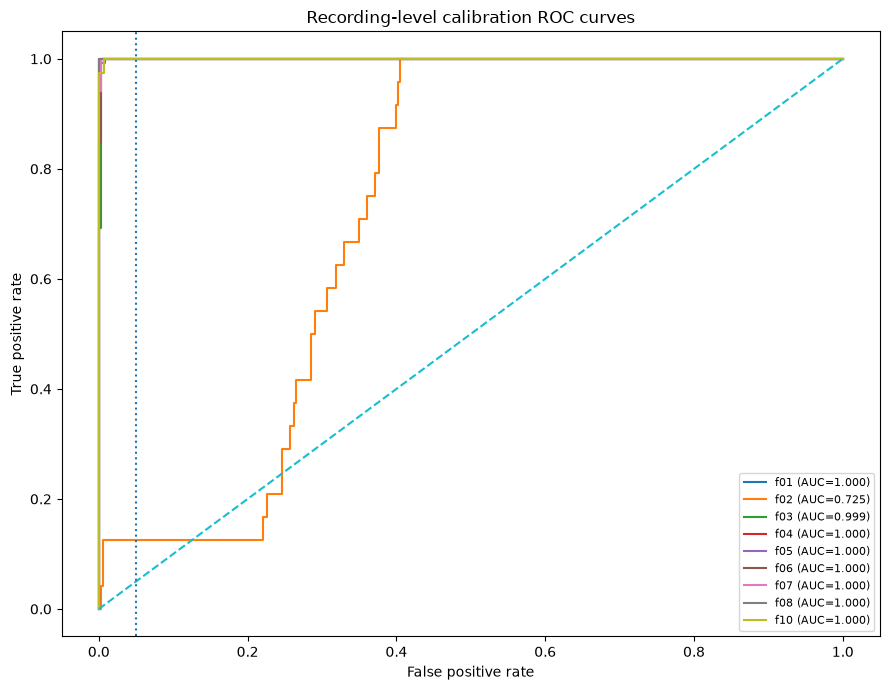

In [12]:
fig, ax = plt.subplots(
    figsize=(9, 7)
)

for code in USABLE_CODES:

    table = roc_tables[
        code
    ]

    auc_value = float(
        threshold_table.loc[
            threshold_table[
                "code"
            ] == code,
            "AUROC",
        ].iloc[0]
    )

    ax.plot(
        table[
            "fpr"
        ],
        table[
            "tpr"
        ],
        label=(
            f"{code} "
            f"(AUC={auc_value:.3f})"
        ),
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

ax.axvline(
    TARGET_MAX_FPR,
    linestyle=":",
)

ax.set(
    title="Recording-level calibration ROC curves",
    xlabel="False positive rate",
    ylabel="True positive rate",
)

ax.legend(
    loc="lower right",
    fontsize=8,
)

plt.tight_layout()
plt.show()

## 13. End-to-end detector decision on calibration calls

The actual detector does two things:

1. identify the highest-scoring GMM hypothesis;
2. verify that hypothesis with the threshold belonging to that species.

A call is accepted only if:

\[
LLR_{\hat{k}}(X)
\ge
	heta_{\hat{k}}.
\]

In [13]:
def detector_decision_from_row(
    row,
):
    hypothesis = row[
        "hypothesis"
    ]

    llr = float(
        row[
            f"llr_{hypothesis}"
        ]
    )

    threshold = float(
        THRESHOLDS[
            hypothesis
        ]
    )

    accepted = (
        llr >= threshold
    )

    predicted_code = (
        hypothesis
        if accepted
        else None
    )

    return pd.Series({
        "hypothesis_llr":
            llr,
        "hypothesis_threshold":
            threshold,
        "accepted":
            accepted,
        "detector_prediction":
            predicted_code,
        "correct_and_accepted":
            accepted
            and (
                hypothesis
                == row[
                    "true_code"
                ]
            ),
    })


decision_columns = (
    calibration_scores
    .apply(
        detector_decision_from_row,
        axis=1,
    )
)

calibration_detector = pd.concat(
    [
        calibration_scores,
        decision_columns,
    ],
    axis=1,
)

display(
    calibration_detector[
        [
            "call_id",
            "true_code",
            "hypothesis",
            "hypothesis_llr",
            "hypothesis_threshold",
            "accepted",
            "detector_prediction",
            "correct_and_accepted",
        ]
    ].head(20)
)

,call_id,true_code,hypothesis,hypothesis_llr,hypothesis_threshold,accepted,detector_prediction,correct_and_accepted
0,call_0060,f01,f01,9.957461,8.075132,True,f01,True
1,call_0061,f01,f01,9.636532,8.075132,True,f01,True
2,call_0062,f01,f01,11.304742,8.075132,True,f01,True
3,call_0063,f01,f01,11.497761,8.075132,True,f01,True
4,call_0064,f01,f01,10.760583,8.075132,True,f01,True
5,call_0065,f01,f01,9.513212,8.075132,True,f01,True
6,call_0066,f01,f01,10.979954,8.075132,True,f01,True
7,call_0067,f01,f01,10.786847,8.075132,True,f01,True
8,call_0068,f01,f01,12.520316,8.075132,True,f01,True
9,call_0069,f01,f01,8.749988,8.075132,True,f01,True


## 14. End-to-end detector metrics

For each species `k`, a positive detector event means:

> the winning hypothesis is `k` **and** that hypothesis passes threshold `theta_k`.

This produces class-specific TP/FP/FN/TN counts for the actual identification-plus-verification
pipeline.

In [14]:
metric_rows = []

for code in USABLE_CODES:

    true_positive_class = (
        calibration_detector[
            "true_code"
        ] == code
    )

    detector_positive_class = (
        calibration_detector[
            "detector_prediction"
        ] == code
    )

    TP = int(
        (
            true_positive_class
            & detector_positive_class
        ).sum()
    )

    FN = int(
        (
            true_positive_class
            & ~detector_positive_class
        ).sum()
    )

    FP = int(
        (
            ~true_positive_class
            & detector_positive_class
        ).sum()
    )

    TN = int(
        (
            ~true_positive_class
            & ~detector_positive_class
        ).sum()
    )

    recall = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else np.nan
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else np.nan
    )

    fpr = (
        FP / (FP + TN)
        if (FP + TN) > 0
        else np.nan
    )

    specificity = (
        TN / (TN + FP)
        if (TN + FP) > 0
        else np.nan
    )

    f1 = (
        2
        * precision
        * recall
        / (
            precision
            + recall
        )
        if (
            np.isfinite(
                precision
            )
            and np.isfinite(
                recall
            )
            and (
                precision
                + recall
            ) > 0
        )
        else np.nan
    )

    metric_rows.append({
        "code":
            code,
        "TP":
            TP,
        "FN":
            FN,
        "FP":
            FP,
        "TN":
            TN,
        "recall":
            recall,
        "precision":
            precision,
        "F1":
            f1,
        "FPR":
            fpr,
        "specificity":
            specificity,
    })

detector_metrics = pd.DataFrame(
    metric_rows
)

display(
    detector_metrics.round(4)
)

macro_metrics = pd.DataFrame([
    {
        "raw_identification_accuracy":
            calibration_detector[
                "identification_correct"
            ].mean(),
        "accepted_fraction":
            calibration_detector[
                "accepted"
            ].mean(),
        "correct_and_accepted_fraction":
            calibration_detector[
                "correct_and_accepted"
            ].mean(),
        "macro_recall":
            detector_metrics[
                "recall"
            ].mean(),
        "macro_precision":
            detector_metrics[
                "precision"
            ].mean(),
        "macro_F1":
            detector_metrics[
                "F1"
            ].mean(),
        "macro_specificity":
            detector_metrics[
                "specificity"
            ].mean(),
        "macro_FPR":
            detector_metrics[
                "FPR"
            ].mean(),
    }
])

display(
    macro_metrics.round(4)
)

,code,TP,FN,FP,TN,recall,precision,F1,FPR,specificity
0,f01,19,0,0,363,1.0000,1.0000,1.0000,0.0000,1.0000
1,f02,3,21,2,356,0.1250,0.6000,0.2069,0.0056,0.9944
2,f03,26,0,0,356,1.0000,1.0000,1.0000,0.0000,1.0000
3,f04,46,1,0,335,0.9787,1.0000,0.9892,0.0000,1.0000
4,f05,129,6,1,246,0.9556,0.9923,0.9736,0.0040,0.9960
5,f06,13,0,0,369,1.0000,1.0000,1.0000,0.0000,1.0000
6,f07,17,0,0,365,1.0000,1.0000,1.0000,0.0000,1.0000
7,f08,25,0,0,357,1.0000,1.0000,1.0000,0.0000,1.0000
8,f10,76,0,1,305,1.0000,0.9870,0.9935,0.0033,0.9967


,raw_identification_accuracy,accepted_fraction,correct_and_accepted_fraction,macro_recall,macro_precision,macro_F1,macro_specificity,macro_FPR
0,0.9764,0.9372,0.9267,0.8955,0.9533,0.907,0.9986,0.0014


## 15. Identification confusion matrix

This matrix intentionally ignores rejection and shows only which frozen GMM wins before thresholding.
It helps distinguish **classification confusion** from **verification rejection**.

In [15]:
cm = confusion_matrix(
    calibration_detector[
        "true_code"
    ],
    calibration_detector[
        "hypothesis"
    ],
    labels=list(
        USABLE_CODES
    ),
)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"true_{code}"
        for code in USABLE_CODES
    ],
    columns=[
        f"pred_{code}"
        for code in USABLE_CODES
    ],
)

display(
    cm_df
)

,pred_f01,pred_f02,pred_f03,pred_f04,pred_f05,pred_f06,pred_f07,pred_f08,pred_f10
true_f01,19,0,0,0,0,0,0,0,0
true_f02,0,22,0,0,2,0,0,0,0
true_f03,0,0,26,0,0,0,0,0,0
true_f04,0,1,0,46,0,0,0,0,0
true_f05,0,3,0,0,129,0,0,0,3
true_f06,0,0,0,0,0,13,0,0,0
true_f07,0,0,0,0,0,0,17,0,0
true_f08,0,0,0,0,0,0,0,25,0
true_f10,0,0,0,0,0,0,0,0,76


## 16. Compare with the paper's published thresholds

The paper's final threshold vector is shown for provenance only:

`[5, 3, 6, 9, 6.75, 5.25, 5.5, 11, 6, 6]`

Those values belong to the paper's own m-FCC/GMM score distributions. Because our final representation
and model order differ, direct numerical transfer would be invalid.

`f09` is also unavailable in our recovered labelled corpus.

In [16]:
PAPER_THRESHOLD_REFERENCE = {
    "f01": 5.0,
    "f02": 3.0,
    "f03": 6.0,
    "f04": 9.0,
    "f05": 6.75,
    "f06": 5.25,
    "f07": 5.5,
    "f08": 11.0,
    "f09": 6.0,
    "f10": 6.0,
}

paper_vs_final_thresholds = pd.DataFrame([
    {
        "code":
            code,
        "paper_threshold_reference":
            PAPER_THRESHOLD_REFERENCE[
                code
            ],
        "our_final_threshold":
            THRESHOLDS.get(
                code,
                np.nan,
            ),
        "used_by_our_detector":
            code in THRESHOLDS,
    }
    for code in PAPER_THRESHOLD_REFERENCE
])

display(
    paper_vs_final_thresholds.round(4)
)

,code,paper_threshold_reference,our_final_threshold,used_by_our_detector
0,f01,5.00,8.0751,True
1,f02,3.00,8.5813,True
2,f03,6.00,6.9382,True
3,f04,9.00,1.9181,True
4,f05,6.75,5.5535,True
5,f06,5.25,5.2310,True
6,f07,5.50,5.7501,True
7,f08,11.00,7.1894,True
8,f09,6.00,NaN,False
9,f10,6.00,9.0146,True


## 17. Smoke test with the frozen model/threshold pair

Take one calibration call, reproduce the full identification + verification decision, and print every
quantity needed to understand the result.

In [17]:
smoke_row = (
    calibration_detector
    .iloc[0]
)

smoke_code = (
    smoke_row[
        "hypothesis"
    ]
)

print("call_id      :", smoke_row["call_id"])
print("true code    :", smoke_row["true_code"])
print("hypothesis   :", smoke_code)
print(
    "LLR          :",
    round(
        float(
            smoke_row[
                "hypothesis_llr"
            ]
        ),
        6,
    ),
)
print(
    "threshold    :",
    round(
        float(
            smoke_row[
                "hypothesis_threshold"
            ]
        ),
        6,
    ),
)
print("accepted     :", bool(smoke_row["accepted"]))
print(
    "correct+acc. :",
    bool(
        smoke_row[
            "correct_and_accepted"
        ]
    ),
)

call_id      : call_0060
true code    : f01
hypothesis   : f01
LLR          : 9.957461
threshold    : 8.075132
accepted     : True
correct+acc. : True


## 18. Serialize the frozen models and thresholds

The saved GMMs are **the same model objects** used to produce every calibration score above.
No retraining occurs after threshold selection.

This coupling is the main safeguard against threshold-transfer score shift.

In [18]:
# Clear any older files from this model directory so stale models cannot be mixed in.
for old_path in MODEL_DIR.glob(
    "*.joblib"
):
    old_path.unlink()

for code, model in FINAL_MODELS.items():

    joblib.dump(
        model,
        MODEL_DIR
        / f"{code}.joblib",
        compress=3,
    )

with open(
    MODEL_DIR
    / "thresholds.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        THRESHOLDS,
        f,
        indent=2,
    )

with open(
    MODEL_DIR
    / "detector_metadata.json",
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        {
            "feature":
                FEATURE_NAME,
            "feature_dimensions":
                FEATURE_DIM,
            "n_components":
                N_COMPONENTS,
            "classes":
                list(
                    USABLE_CODES
                ),
            "excluded_class":
                EXCLUDED_CLASS,
            "training_unit":
                "source_wav",
            "calibration_unit":
                "source_wav",
            "train_calibration_recordings_disjoint":
                True,
            "calibration_target_max_FPR":
                TARGET_MAX_FPR,
            "experimental_training_target_seconds_from_06B":
                EXPERIMENTAL_TRAINING_TARGET_SECONDS,
            "final_gmm_training_policy":
                (
                    "all labelled calls from TRAIN recordings; "
                    "models frozen before threshold calibration"
                ),
            "llr_definition":
                (
                    "class mean log-likelihood minus median "
                    "mean log-likelihood of all alternative models"
                ),
            "paper_reference":
                {
                    "feature":
                        "20_mFCC",
                    "n_components":
                        64,
                    "thresholds":
                        PAPER_THRESHOLD_REFERENCE,
                },
            "evaluation_limitations":
                [
                    (
                        "thresholds and calibration metrics use the same "
                        "held-out CALIBRATION recordings"
                    ),
                    (
                        "calibration negatives are other modelled frog calls, "
                        "not environmental noise or unmodelled species"
                    ),
                    (
                        "f09 excluded because recovered labelled material is insufficient"
                    ),
                ],
        },
        f,
        indent=2,
    )

print("Frozen detector saved to:", MODEL_DIR)

for path in sorted(
    MODEL_DIR.iterdir()
):
    print(
        " ",
        path.name,
    )

Frozen detector saved to: C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_robust_final
  detector_metadata.json
  f01.joblib
  f02.joblib
  f03.joblib
  f04.joblib
  f05.joblib
  f06.joblib
  f07.joblib
  f08.joblib
  f10.joblib
  thresholds.json


## 19. Save calibration tables and split provenance

In [19]:
split_audit.to_csv(
    RESULTS_DIR
    / "train_calibration_split_audit.csv",
    index=False,
)

train_calls[
    [
        "call_id",
        "code",
        "species",
        "wav",
        "recording_group",
        "seconds",
    ]
].to_csv(
    RESULTS_DIR
    / "train_calls.csv",
    index=False,
)

calibration_calls[
    [
        "call_id",
        "code",
        "species",
        "wav",
        "recording_group",
        "seconds",
    ]
].to_csv(
    RESULTS_DIR
    / "calibration_calls.csv",
    index=False,
)

calibration_scores.to_csv(
    RESULTS_DIR
    / "calibration_scores_and_llr.csv",
    index=False,
)

threshold_table.to_csv(
    RESULTS_DIR
    / "thresholds_and_roc_operating_points.csv",
    index=False,
)

calibration_detector.to_csv(
    RESULTS_DIR
    / "calibration_detector_decisions.csv",
    index=False,
)

detector_metrics.to_csv(
    RESULTS_DIR
    / "calibration_detector_metrics_by_species.csv",
    index=False,
)

macro_metrics.to_csv(
    RESULTS_DIR
    / "calibration_macro_metrics.csv",
    index=False,
)

cm_df.to_csv(
    RESULTS_DIR
    / "identification_confusion_matrix.csv",
)

paper_vs_final_thresholds.to_csv(
    RESULTS_DIR
    / "paper_vs_final_thresholds.csv",
    index=False,
)

for code, roc_table in roc_tables.items():
    roc_table.to_csv(
        RESULTS_DIR
        / f"roc_{code}.csv",
        index=False,
    )

split_payload = {
    "train_recordings":
        sorted(
            TRAIN_RECORDINGS
        ),
    "calibration_recordings":
        sorted(
            CALIBRATION_RECORDINGS
        ),
    "split_seed":
        SPLIT_SEED,
    "split_search_attempts":
        SPLIT_SEARCH_ATTEMPTS,
    "selected_attempt":
        int(
            best_split[
                "attempt"
            ]
        ),
    "calibration_fraction_target":
        CALIBRATION_FRACTION_TARGET,
}

with open(
    RESULTS_DIR
    / "train_calibration_recordings.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        split_payload,
        f,
        indent=2,
    )

print("Saved calibration outputs:")

for path in sorted(
    RESULTS_DIR.iterdir()
):
    print(
        f"  {path.name:<44} "
        f"{path.stat().st_size / 1e6:>8.3f} MB"
    )

Saved calibration outputs:
  calibration_calls.csv                           0.043 MB
  calibration_detector_decisions.csv              0.193 MB
  calibration_detector_metrics_by_species.csv     0.001 MB
  calibration_macro_metrics.csv                   0.000 MB
  calibration_scores_and_llr.csv                  0.174 MB
  identification_confusion_matrix.csv             0.000 MB
  paper_vs_final_thresholds.csv                   0.000 MB
  roc_f01.csv                                     0.000 MB
  roc_f02.csv                                     0.002 MB
  roc_f03.csv                                     0.000 MB
  roc_f04.csv                                     0.000 MB
  roc_f05.csv                                     0.000 MB
  roc_f06.csv                                     0.000 MB
  roc_f07.csv                                     0.000 MB
  roc_f08.csv                                     0.000 MB
  roc_f10.csv                                     0.000 MB
  thresholds_and_roc_operatin

## 20. Final detector status

If all cells complete successfully, the project now has a frozen robust detector:

- feature representation selected under recording-level validation;
- model order selected under recording-level validation;
- one frozen diagonal GMM per species;
- no source-WAV overlap between TRAIN and CALIBRATION;
- one-vs-all LLR verification;
- one ROC-derived threshold per species;
- no retraining after threshold selection;
- GMMs and thresholds serialized together.

### What this detector is ready for

It is ready for **call-level inference using already segmented candidate calls** represented with the
same selected feature extraction pipeline.

### What it is not yet ready to claim

It has not yet been independently tested against realistic environmental negatives such as:

- rain;
- insects;
- birds;
- human speech;
- unmodelled frog species;
- overlapping calls.

Therefore the calibration metrics above should not be presented as final field presence/absence
performance.

### Next methodological step

Before long-recording presence/absence inference, validate or reconstruct the **candidate-call
segmentation frontend** separately. That stage should not be allowed to hide feature or detector errors
by tuning segmentation until the output merely looks plausible. Humanity has invented enough knobs
already.